#Pytorch_With_Classification

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from torch.utils.data import TensorDataset, DataLoader



In [ ]:
# Load dataset
df = pd.read_csv("/content/iris.csv")
df.drop('petal length (cm)', axis=1, inplace=True)
df.drop('petal width (cm)', axis=1, inplace=True)
df.head()

,sepal length (cm),sepal width (cm),target
0,5.1,3.5,0
1,4.9,3.0,0
2,4.7,3.2,0
3,4.6,3.1,0
4,5.0,3.6,0


In [ ]:
# Features and target
X = df.drop('target', axis=1)
y = df['target']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)


In [ ]:
X.shape , y.shape

((150, 2), (150,))

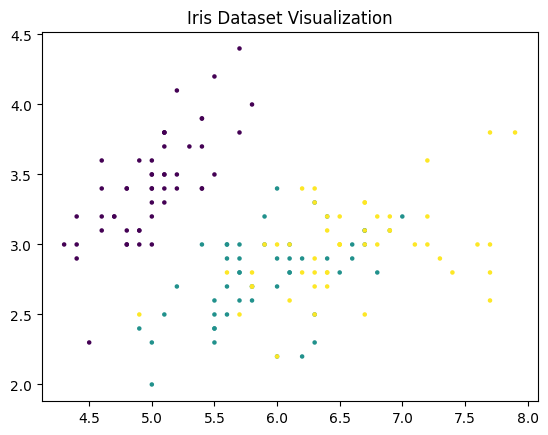

In [ ]:
# visualisation
import matplotlib.pyplot as plt
plt.scatter(x=X.iloc[:, 0], y=X.iloc[:, 1], s=5, c=y)
plt.title('Iris Dataset Visualization')
plt.show()

Convert numpy to tensor

CrossEntropyLoss -- traget -- int (long)

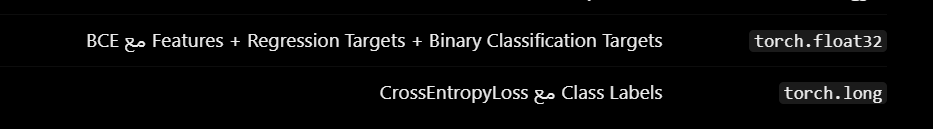

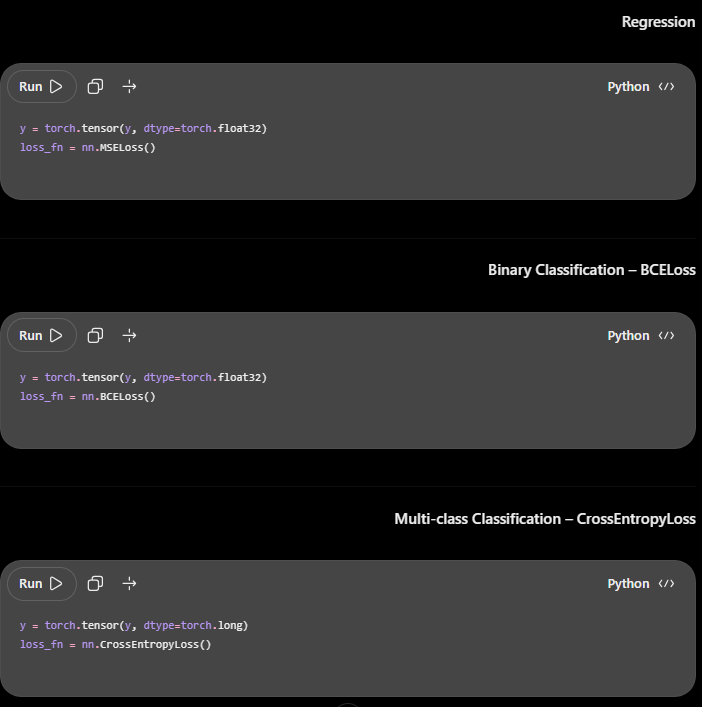

In [ ]:
X_train = torch.tensor(X_train.values, dtype=torch.float32)
X_test = torch.tensor(X_test.values, dtype=torch.float32)
y_train = torch.tensor(y_train.values, dtype=torch.long)
y_test = torch.tensor(y_test.values, dtype=torch.long)

In [ ]:
type(X_train)

torch.Tensor

In [ ]:
# DataLoader
train_dataset = TensorDataset(X_train, y_train)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

We have many ways to build our NN

In [ ]:
model = nn.Sequential(
    nn.Linear(X_train.shape[1], 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 3))

print(model)

Sequential(
  (0): Linear(in_features=2, out_features=64, bias=True)
  (1): ReLU()
  (2): Linear(in_features=64, out_features=32, bias=True)
  (3): ReLU()
  (4): Linear(in_features=32, out_features=3, bias=True)
)


In [ ]:
class Classification(nn.Module):

    def __init__(self):
        super().__init__()

        # Input Layer -> Hidden Layer
        self.fc1 = nn.Linear(X_train.shape[1], 64)
        self.relu1 = nn.ReLU()

        # Hidden Layer -> Output Layer
        self.fc2 = nn.Linear(64, 3)

    def forward(self, x):

        # First Hidden Layer
        sum_L1 = self.fc1(x)
        output_L1 = self.relu1(sum_L1)

        # Output Layer
        final_output = self.fc2(output_L1)

        return final_output


model = Classification()

print(model)

Classification(
  (fc1): Linear(in_features=2, out_features=64, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=64, out_features=3, bias=True)
)


In [ ]:
loss_fn = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 50
for epoch in range(epochs):
    for xb, yb in train_loader:
        pred = model(xb)
        loss = loss_fn(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if (epoch+1) % 10 == 0:
        print(f"Epoch {epoch+1}/{epochs}, Loss: {loss.item():.4f}")

Epoch 10/50, Loss: 0.8291
Epoch 20/50, Loss: 0.6801
Epoch 30/50, Loss: 0.6019
Epoch 40/50, Loss: 0.4285
Epoch 50/50, Loss: 0.6964


In [ ]:
import torch
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# 1. Evaluation Mode
model.eval()

# 2. Disable Gradient Calculation
with torch.no_grad():

    # 3. Predictions
    outputs = model(X_test)

    # 4. Get Predicted Classes
    y_pred = torch.argmax(outputs, dim=1)
    #    y_pred = outputs.round()

    # 5. Convert to NumPy
    y_pred = y_pred.numpy()
    y_true = y_test.numpy()

# 6. Evaluation Metrics
print("Accuracy:", accuracy_score(y_true, y_pred))


Accuracy: 0.8666666666666667
